# 맨유 뉴스 EDA 보고서
**캐릭 감독 경질 국면의 국내 보도 분석 (2026년 10월 23일 – 29일)**

| 항목 | 내용 |
|---|---|
| 데이터 출처 | 네이버스포츠 해외축구 뉴스 (목록 API + 기사 API) |
| 기간 | 2026-10-23 00:00 ~ 2026-10-29 오전 (29일은 일부만 집계) |
| 대상 | 제목이나 요약에 '맨유', '맨체스터 유나이티드' 등이 들어간 기사 424건 |
| 수집·분류 코드 | `naver_manutd_news_EDA.ipynb` |

### 요약
1. 일주일 동안 맨유 기사의 **약 절반(49%)이 캐릭 감독 경질** 이야기였습니다.
2. 기사량은 **BBC '후임 물색' 보도(10/23)**와 **본머스전 0-3 패배(10/26)** 때 치솟았습니다.
3. 제목의 **41%가 부정적인 표현**을 썼지만, 부정적인 제목의 조회수가 더 높지는 않았습니다.
4. **경질을 원한 쪽은 전문가와 언론**이었고, **현지 팬 다수는 캐릭을 감싸며 구단주를 비판**했습니다.

## 0. 준비

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='AppleGothic', rc={'axes.unicode_minus': False})
pd.set_option('display.max_colwidth', 90)
RED, GRAY = '#c8102e', '#c9c9c9'

from pathlib import Path

# 노트북이 있는 web_scraping 폴더에서 실행해도, 저장소 최상위에서 실행해도 데이터를 찾도록 경로를 정합니다.
DATA_FILE = 'naver_manutd_articles_enriched_20261023-29.csv'
CANDIDATES = [Path('.'), Path('web_scraping'), Path('..') / 'web_scraping']
BASE = next((p for p in CANDIDATES if (p / DATA_FILE).exists()), None)
if BASE is None:
    raise FileNotFoundError(f'{DATA_FILE}을(를) 찾지 못했습니다. 노트북과 같은 web_scraping 폴더에 CSV가 있는지 확인하세요. 현재 위치: {Path.cwd()}')
print('데이터 폴더:', BASE.resolve())
df = pd.read_csv(BASE / DATA_FILE)
raw = pd.read_csv(BASE / 'naver_manutd_raw_20261023-29.csv', usecols=['id', 'summary'])
df = df.merge(raw, on='id', how='left')
df['datetime'] = pd.to_datetime(df['datetime'])
df.shape

데이터 폴더: /Users/limsunghun/python/DI/web_scraping


(424, 14)

## 1. 데이터 설명

| 열 | 뜻 |
|---|---|
| `datetime`, `date`, `hour` | 기사 작성 시각 (한국 시간) |
| `press`, `reporter` | 언론사, 기자 |
| `title`, `summary` | 제목, 네이버가 제공한 요약 |
| `views` | 수집 시점의 누적 조회수 |
| `manager` | 감독 경질 관련 기사 여부 (경질·유임·후임·거취 등 키워드) |
| `tone` | 제목 톤: 부정 / 중립 / 혼합 / 긍정 (단어 사전 기준, 3장 참고) |
| `positive` | 경질에 긍정적인 기사 여부 (제목·요약을 직접 읽고 고른 19건) |
| `excluded` | 맨유를 유독 부정적으로 쓰는 기자의 기사 여부 |

In [2]:
df[['datetime', 'press', 'reporter', 'title', 'views', 'tone', 'manager']].head()

,datetime,press,reporter,title,views,tone,manager
0,2026-10-29 12:40:06,인터풋볼,이태훈,"캐릭 감독 있을 때 돌아올 수는 있나…부진에 빠진 맨유에 또 초대형 악재! 세슈코, 정강이 부상 재발→최소 내년 1월까지 결장 전망",27,부정,0
1,2026-10-29 12:34:08,마이데일리,김건호,"박지성 절친 충격 폭로! ""퍼거슨 감독이 약속을 어겼다""…맨시티로 이적한 이유 전격 공개",104,중립,0
2,2026-10-29 12:12:09,스포탈코리아,김경태,"""퍼거슨, 내 몸값 깎으려 벤치 앉혔다 생각""...'박지성 절친' 테베스, 맨유 떠나 맨시티 이적 배경 고백 ""일종의 복수""",481,중립,0
3,2026-10-29 12:00:06,마이데일리,노찬혁,"'맙소사' 맨체스터 유나이티드 '초대형 악재'...'1150억 ST' 정강이 부상 재발, 내년 1월까지 결장 확정! 완전 회복 후 복귀 예정",854,부정,0
4,2026-10-29 11:35:09,포포투,김호진,"'맨체스터 유나이티드 초비상!' 세슈코, 올해는 아예 못 뛴다!…정강이 부상으로 최소 내년 1월까지 결장 전망",848,부정,0


In [3]:
print('결측치:', df[['press', 'reporter', 'title', 'views']].isna().sum().to_dict())
df['views'].describe().astype(int).to_frame('조회수')

결측치: {'press': 0, 'reporter': 0, 'title': 0, 'views': 0}


,조회수
count,424
mean,5682
std,7767
min,27
25%,1661
50%,3339
75%,6279
max,73365


## 2. 핵심 지표

In [4]:
kpi = pd.Series({
    '전체 맨유 기사': f'{len(df)}건',
    '언론사 / 기자': f"{df.press.nunique()}곳 / {df.groupby(['press', 'reporter']).ngroups}명",
    '감독 경질 관련': f"{df.manager.sum()}건 ({df.manager.mean():.0%})",
    '부정적인 제목': f"{(df.tone == '부정').sum()}건 ({(df.tone == '부정').mean():.0%})",
    '조회수 중앙값 / 최댓값': f"{int(df.views.median()):,} / {df.views.max():,}",
    '상위 5개 언론사 비중': f"{df.press.value_counts().head(5).sum() / len(df):.0%}",
})
kpi.to_frame('값')

,값
전체 맨유 기사,424건
언론사 / 기자,33곳 / 76명
감독 경질 관련,207건 (49%)
부정적인 제목,174건 (41%)
조회수 중앙값 / 최댓값,"3,339 / 73,365"
상위 5개 언론사 비중,64%


## 3. 기사량의 흐름

### 3-1. 일별 기사량
기사는 두 사건에서 치솟았습니다. 경질 관련 기사의 비중은 유임이 결정된 10/27에 77%로 가장 높았습니다.

,전체,경질관련,기타,경질 비중
date,,,,
2026-10-23,100,36,64,36%
2026-10-24,56,23,33,41%
2026-10-25,37,12,25,32%
2026-10-26,97,61,36,63%
2026-10-27,43,33,10,77%
2026-10-28,58,34,24,59%
2026-10-29,33,8,25,24%


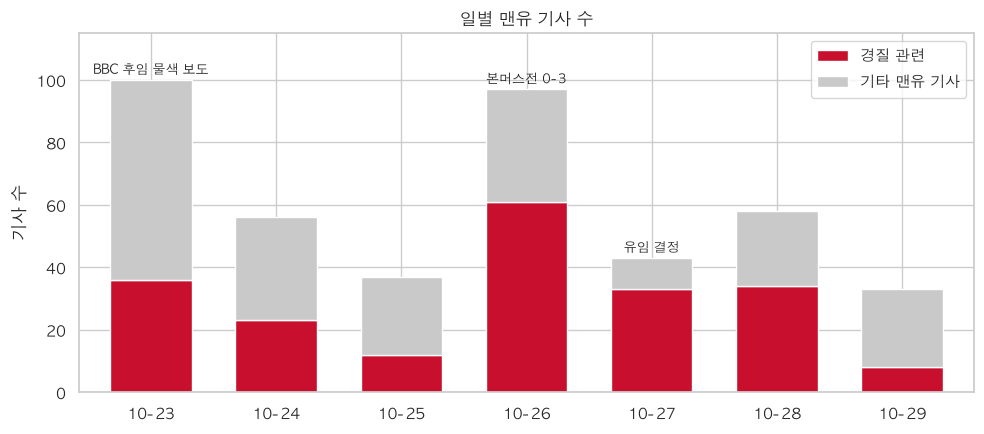

In [5]:
daily = df.groupby('date').agg(전체=('id', 'size'), 경질관련=('manager', 'sum'))
daily['기타'] = daily['전체'] - daily['경질관련']
daily['경질 비중'] = (daily['경질관련'] / daily['전체']).map('{:.0%}'.format)
display(daily)

ax = daily[['경질관련', '기타']].plot.bar(stacked=True, figsize=(10, 4.5), color=[RED, GRAY], width=0.65)
ax.legend(['경질 관련', '기타 맨유 기사'])
events = {'2026-10-23': 'BBC 후임 물색 보도', '2026-10-26': '본머스전 0-3', '2026-10-27': '유임 결정'}
for i, d in enumerate(daily.index):
    if d in events:
        ax.annotate(events[d], (i, daily.loc[d, '전체'] + 2), ha='center', fontsize=9)
ax.set_xticklabels([d[5:] for d in daily.index], rotation=0)
ax.set(title='일별 맨유 기사 수', xlabel='', ylabel='기사 수', ylim=(0, daily['전체'].max() * 1.15))
plt.tight_layout(); plt.show()

### 3-2. 시간대별 기사량
영국 경기가 끝나는 자정 무렵과 현지 보도가 정리되는 아침 7–8시에 기사가 몰립니다.

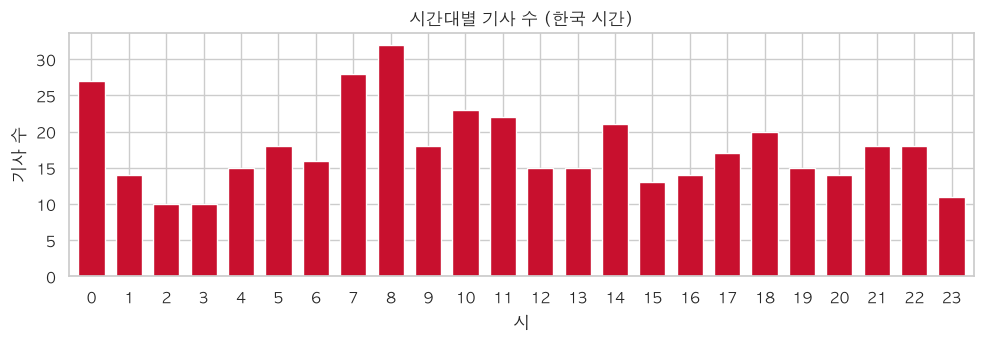

In [6]:
hourly = df.groupby('hour').size().reindex(range(24), fill_value=0)
ax = hourly.plot.bar(figsize=(10, 3.6), color=RED, width=0.7)
ax.set(title='시간대별 기사 수 (한국 시간)', xlabel='시', ylabel='기사 수')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. 누가 쓰고, 누가 언급됐나

### 4-1. 언론사
상위 다섯 곳이 전체 기사의 64%를 썼고, 마이데일리 혼자 80건(19%)을 썼습니다.

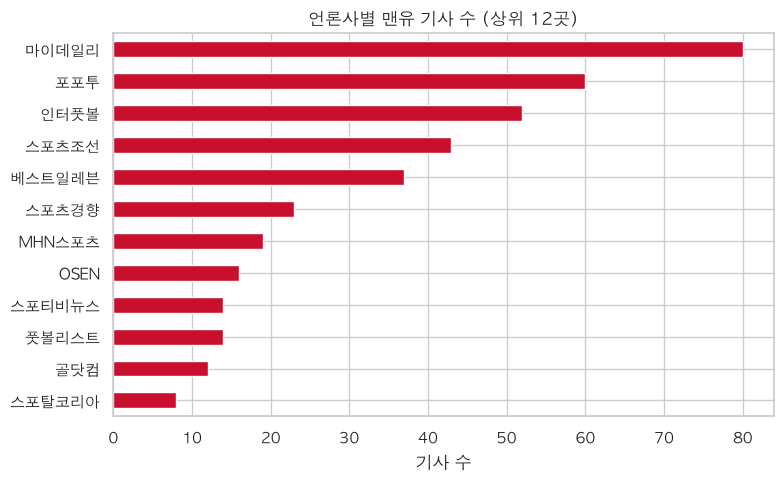

In [7]:
ax = df.press.value_counts().head(12).sort_values().plot.barh(figsize=(8, 5), color=RED)
ax.set(title='언론사별 맨유 기사 수 (상위 12곳)', xlabel='기사 수', ylabel='')
plt.tight_layout(); plt.show()

### 4-2. 제목에 등장한 인물
후임 후보 중에서는 나겔스만과 하우가 비슷하게 많이 거론됐습니다. 브루노 페르난데스가 73건으로 많은 것은 캐릭과의 불화가 경질 국면의 또 다른 축이었기 때문입니다.

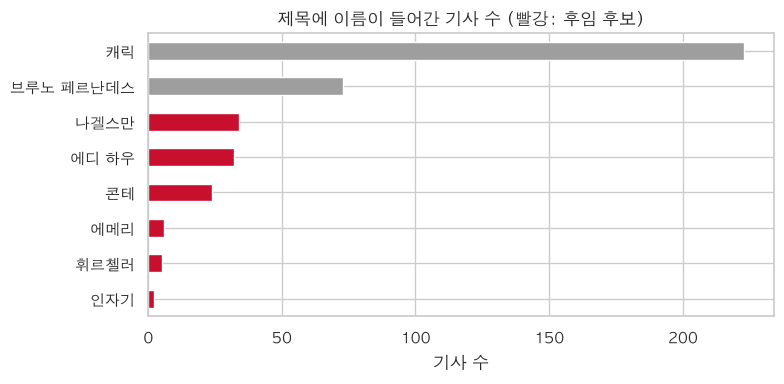

In [8]:
PEOPLE = {'캐릭': '캐릭', '브루노 페르난데스': '브루노|페르난데스', '나겔스만': '나겔스만', '에디 하우': '하우',
          '콘테': '콘테', '에메리': '에메리', '휘르첼러': '휘르첼러', '인자기': '인자기'}
CANDIDATES = {'나겔스만', '에디 하우', '콘테', '에메리', '휘르첼러', '인자기'}
people = pd.Series({k: df.title.str.contains(v).sum() for k, v in PEOPLE.items()}).sort_values()
ax = people.plot.barh(figsize=(8, 4), color=[RED if k in CANDIDATES else '#9e9e9e' for k in people.index])
ax.set(title='제목에 이름이 들어간 기사 수 (빨강: 후임 후보)', xlabel='기사 수', ylabel='')
plt.tight_layout(); plt.show()

## 5. 제목 톤과 조회수

### 5-1. 톤은 어떻게 분류했나
수집한 제목을 직접 읽으면서 맨유를 나쁘게 또는 좋게 묘사할 때 반복해서 나오는 표현을 골라 **단어 사전**을 만들었습니다. 통계나 모델로 뽑은 단어가 아닌 규칙 기반 분류입니다. 제목에 부정 단어만 있으면 `부정`, 긍정 단어만 있으면 `긍정`, 둘 다 있으면 `혼합`, 둘 다 없으면 `중립`입니다.

**부정 단어 (57개)**
| 묶음 | 예시 | 넣은 이유 |
|---|---|---|
| ① 나쁜 결과·순위 | 참패, 대패, 졸전, 추락, 강등, 최저 | 경기 결과나 순위가 나쁘다는 것을 강조 |
| ② 구단 내부 갈등 | 내분, 분열, 불화, 항명, 저격, 비판, 통제 불능, 콩가루 | 구단이 흔들린다는 프레임 |
| ③ 감정적·비하 표현 | 망했, 폭망, 굴욕, 맙소사, 최악, 무능, 맨유했, 꺼져 | 사실 전달보다 조롱·자극에 가까움 |

**긍정 단어 (18개)**: 반등, 부활, 희망, 화해, 지지, 극찬, 호평, 청신호, 영웅, 자존심, 맹활약, 폭발(뒤에 '분노'가 오면 제외) 등.

**일부러 뺀 단어**
- '충격': 제목 55건에 쓰였지만 부정·중립·긍정 기사에 고루 붙는 상투어라 톤을 구분하지 못합니다.
- '경질': 사건 자체를 가리키는 말이라 톤이 아닌 '경질 관련' 분류로 다뤘습니다.
- '파격', '대반전', '속보': 방향 없이 주목만 끄는 표현입니다.

### 5-2. 톤 분포와 톤별 조회수
부정적인 제목이 가장 많지만, 톤마다 조회수 중앙값의 차이는 크지 않습니다. **자극적인 제목이 클릭을 보장하지는 않았습니다.** 조회수는 한쪽으로 크게 치우쳐 있어(최댓값 7만 3천) 평균 대신 중앙값과 로그 축을 씁니다.

,기사수,조회수중앙값,조회수평균,비중
tone,,,,
부정,174,3448,5217,41%
중립,197,3082,6007,46%
혼합,25,4280,6123,6%
긍정,28,3732,5888,7%


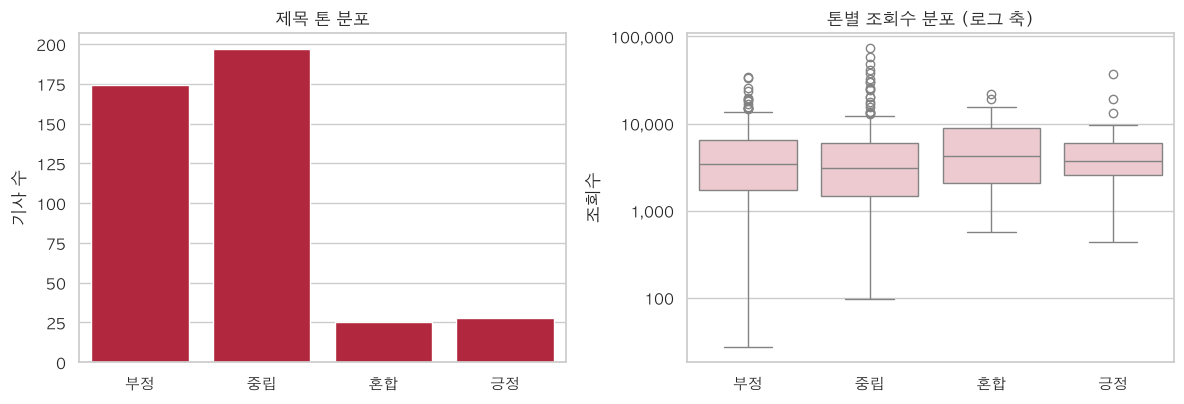

In [9]:
ORDER = ['부정', '중립', '혼합', '긍정']
tone_stat = df.groupby('tone').views.agg(기사수='size', 조회수중앙값='median', 조회수평균='mean').reindex(ORDER).astype(int)
tone_stat['비중'] = (tone_stat['기사수'] / len(df)).map('{:.0%}'.format)
display(tone_stat)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.countplot(data=df, x='tone', order=ORDER, ax=axes[0], color=RED)
axes[0].set(title='제목 톤 분포', xlabel='', ylabel='기사 수')
sns.boxplot(data=df, x='tone', y='views', order=ORDER, ax=axes[1], color='#f2c4cb')
axes[1].set_yscale('log')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'{int(v):,}'))
axes[1].set(title='톤별 조회수 분포 (로그 축)', xlabel='', ylabel='조회수')
plt.tight_layout(); plt.show()

### 5-3. 톤 분류의 한계
- **'폭발'이 긍정 단어 중 가장 많이 걸렸지만(21건) 부정 맥락이 많습니다.** "갈등 폭발", "경질설 폭발", "인내심 폭발"이 긍정으로 잘못 분류됐습니다.
- **'승리', '기대'도 문맥을 놓칩니다.** "승리를 잊은 맨유", "기대 승점보다… 운이 좋았던 것뿐"이 긍정이 됐습니다.
- **'비판'과 '저격'(각 30건)**은 주로 브루노가 캐릭을 비판한 사건을 전한 제목이라, 기자의 논조라기보다 사건 묘사입니다.
- 부정 사전(57개)이 긍정 사전(18개)보다 커서 부정으로 분류되기 쉬운 편향이 있습니다.

In [10]:
MISLABELED = ['인내심 폭발', '승리를 잊은', '갈등 폭발', '현지 기자 폭발', '경질설 폭발', '기대 승점']
mis = df[(df.tone == '긍정') & df.title.str.contains('|'.join(MISLABELED))]
print(f"긍정 {(df.tone == '긍정').sum()}건 중 문맥상 부정: {len(mis)}건")
mis[['press', 'title']].reset_index(drop=True)

긍정 28건 중 문맥상 부정: 6건


,press,title
0,포포투,"""맨유 지난 시즌 3위? 사실 운이 좋았던 것뿐!""…英 '가디언'의 진단! '기대 승점보다 12.7점 더 획득' 캐릭의 성공 뒤에 숨겨진 진실"
1,마이데일리,"맨체스터 유나이티드 인내심 폭발! '감독 교체' 카운트다운...'8G 무승' 48시간 내 캐릭 경질 예정, 임원 '긴급 회의'까지 소집"
2,OSEN,"'감독 교체 본격화' 승리를 잊은 맨유, 마이클 캐릭 후임 2명으로 압축...""나겔스만 or 에디 하우"""
3,스포츠조선,"충격 결단! '손흥민 주장 박탈급' 사고 터지나, 선수-감독 갈등 폭발...캐릭 감독, 마침내 브루노 완장 압수도 고려 ""구단에 최선인 결정할 것"""
4,스포탈코리아,"""브루노 대신 16세 루니 아들 써라!"" 맨유 충격의 7경기 무승→현지 기자 폭발...""고액 연봉 선수들 전부 빼!"""
5,인터풋볼,"맨유 11경기 2승+7경기 무승에 캐릭 경질설 폭발…차기 감독으로 '39세 천재 사령탑' 나겔스만 급부상→""제안 온다면 들어볼 의향 있다"""


## 6. 기자별 부정 제목 비율
맨유 기사를 5건 이상 쓴 기자만 비교했습니다. 빨간 막대는 부정 비율이 60% 이상이어서 필터링 파일에서 제외한 기자 6명입니다. 전체 평균은 41%입니다.

5장의 톤 분류 한계 때문에 이 비율은 참고용입니다. 기사가 5–6건인 기자는 한두 건 차이로 순위가 바뀔 수 있습니다. 근거가 가장 뚜렷한 기자는 기사가 31건으로 많은 마이데일리 노찬혁 기자입니다.

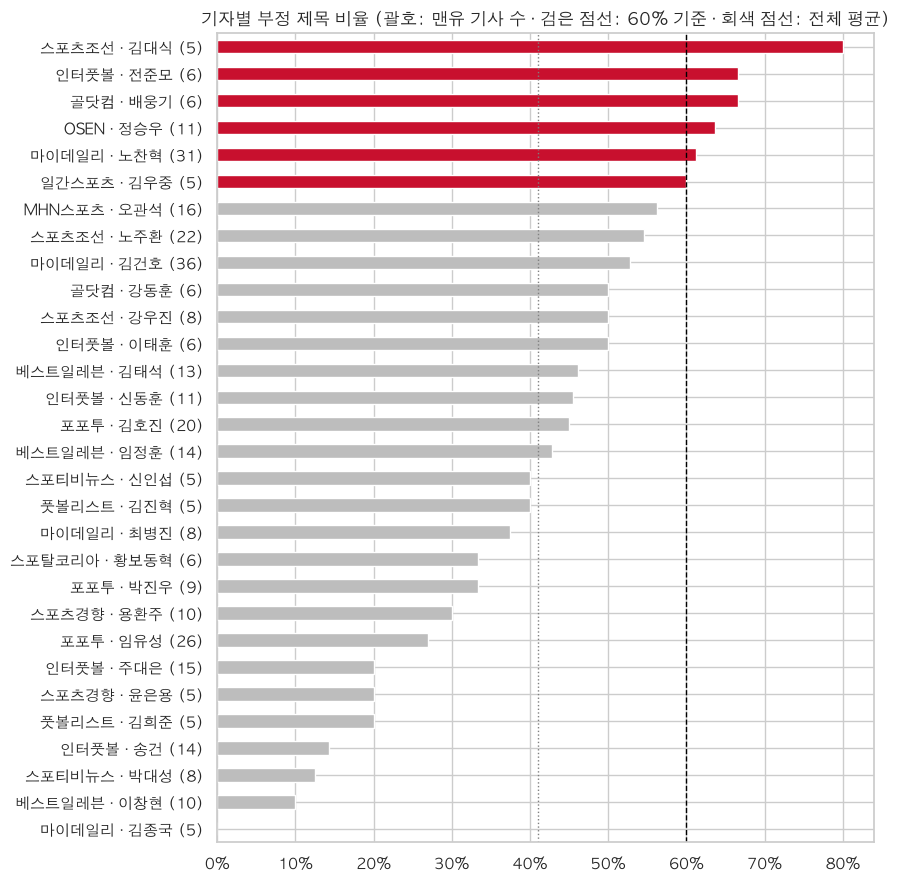

In [11]:
rep = (df.groupby(['press', 'reporter'])
         .agg(n=('id', 'size'), neg=('tone', lambda s: (s == '부정').mean()))
         .reset_index().query('n >= 5').sort_values('neg'))
rep['label'] = rep.press + ' · ' + rep.reporter + ' (' + rep.n.astype(str) + ')'
ax = rep.plot.barh(x='label', y='neg', figsize=(9, 9), legend=False,
                   color=[RED if v >= 0.6 else '#bdbdbd' for v in rep.neg])
ax.axvline(0.6, color='black', ls='--', lw=1)
ax.axvline((df.tone == '부정').mean(), color='gray', ls=':', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set(title='기자별 부정 제목 비율 (괄호: 맨유 기사 수 · 검은 점선: 60% 기준 · 회색 점선: 전체 평균)', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

## 7. 가장 많이 읽힌 기사
조회수 상위 기사는 전술 분석보다 팬 이야기, 감독 후보설, 경질 속보 쪽에 몰려 있습니다. 1·2위가 모두 한 팬의 기행을 다룬 기사입니다.

In [12]:
df.nlargest(10, 'views')[['date', 'press', 'views', 'title']].reset_index(drop=True)

,date,press,views,title
0,2026-10-25,엑스포츠뉴스,73365,"'감독 경질 될 때까지 매일 가슴 공개!'…맨유 미녀 서포터 파격 선언에 난리→팬들은 ""캐릭 종신! 재계약 추진하자"""
1,2026-10-28,OSEN,58617,“캐릭 경질될 때까지 매일 가슴 사진 올린다”…맨유 팬의 파격 선언에 팬들 “캐릭 제발 계속 감독해라”
2,2026-10-26,마이데일리,48539,"이럴 수가! '충격 그 자체'...맨체스터 유나이티드 '드림 감독'으로 낙점! ""단장이 매우 높게 평가""→이미 지난 해에도 러브콜 보냈다"
3,2026-10-24,스포티비뉴스,41156,"‘오피셜’ 공식발표, 캐릭 맨체스터 유나이티드 감독 경질→후임으로 거론됐던 콘테 “진전된 협상 전혀 없다, 근거없는 보도” 정면 반박"
4,2026-10-27,MHN스포츠,37912,맨체스터 유나이티드 결국 '파격 결단' 임박! '3무 5패' 캐릭 경질→차기 감독 선임 작업 착수...나겔스만·하우 2파전
5,2026-10-23,마이데일리,36858,"말 그대로 '초대박'...맨체스터 유나이티드 '감독 교체' 청신호! 'HERE WE GO' 캐릭 경질→'쏘니 전 스승' 후임 가능, ""시즌 도중 부임도 OK"""
6,2026-10-24,마이데일리,34125,"말 그대로 '미친 영입'...맨체스터 유나이티드 '브페 후계자' 낙점! '2골 1도움' 참사 안긴 '제2의 메시' 러브콜, 레알 '바이백 조항' 최대 변수"
7,2026-10-25,마이데일리,33534,"'처참하다' 캐릭의 결단 '악수'로...맨체스터 유나이티드, '돌아온 골칫거리' 겨울에 결국 매각한다! ""에버턴과 겨울 이적 협상 진행"""
8,2026-10-26,포포투,32029,"[오피셜] 맨유 처참하게 무너뜨린 코모의 '그리스 폭격기', 2031년까지 재계약"
9,2026-10-26,마이데일리,30146,"세상에! 결국 '깜짝 임대?'...맨체스터 유나이티드, '라이벌' 맨시티 LB 다시 노린다→EPL 출전 '0회'로 입지 '대위기'"


## 8. 결론: 대중은 캐릭 경질을 어떻게 보나

이 데이터는 여론조사나 댓글이 아니라 **기사**입니다. 그래서 기사가 전한 반응을 주체별로 나눠 봅니다.

### 8-1. 현지 팬의 반응을 다룬 경질 관련 기사

In [13]:
text = df['title'] + ' ' + df['summary'].fillna('')
fans = df[text.str.contains(r'팬|서포터|관중|연호|응원|야유') & (df.manager == 1)].sort_values('datetime')
fans[['date', 'press', 'title']].reset_index(drop=True)

,date,press,title
0,2026-10-23,골닷컴,[속보] ‘7경기 무승’ 맨체스터 유나이티드 팬들 바람 끝내 이뤄지지 않는다…‘비피셜’ 英 BBC “경기력·결과 우려에도 캐릭 감독 지휘봉 계속 잡을 예정”
1,2026-10-23,스포츠경향,두 손 든 사령탑 공개 저격한 주장 막장 ‘맨유 극장’
2,2026-10-25,엑스포츠뉴스,"'감독 경질 될 때까지 매일 가슴 공개!'…맨유 미녀 서포터 파격 선언에 난리→팬들은 ""캐릭 종신! 재계약 추진하자"""
3,2026-10-26,이데일리,0-3 패했는데 캐릭 응원구호...구단 경영진 향한 맨유 팬들 분노
4,2026-10-26,스포츠경향,"스카이스포츠 “캐릭, 24~48시간 내 경질 전망”"
5,2026-10-26,마이데일리,"'패패무무패무패패' 캐릭 매직 진짜 끝났다…""24시간 안에 경질될 것"" 맨체스터 유나이티드 레전드 확신"
6,2026-10-26,베스트일레븐,"'캐릭! 캐릭!' 0-3 참패에도 감독 연호한 현지 맨유 팬들… 선수들에겐 야유 세례 ""감독만의 문제 아니다"""
7,2026-10-26,더게이트,"8G 연속 무승-2G 연속 참패인데 감독 향해 박수가...맨유 팬들 ""구단 팔고 꺼져라!"" 구단주에 분노 폭발"
8,2026-10-26,스포츠경향,"팬들은 캐릭 연호하며 박수 보내…무너진 맨유, 감독 교체가 정답일까"
9,2026-10-26,스포티비뉴스,“캐릭만 바꾸면 끝인가” 맨유 팬들 분노 폭발…0-3 참패에도 사령탑 연호→진짜 화살은 구단 수뇌부로


### 8-2. 레전드·전문가·언론 칼럼을 다룬 경질 관련 기사

In [14]:
pundits = df[text.str.contains(r'레전드|캐러거|네빌|칼럼|편집장|전문가|리네커|로이 킨|시세') & (df.manager == 1)].sort_values('datetime')
pundits[['date', 'press', 'title']].reset_index(drop=True)

,date,press,title
0,2026-10-23,스포츠조선,"'충격 졸전 영향' 캐릭 맨유 감독 파격 경질 현실화! 로마노 피셜…""팀을 다른 국면으로 몰아 넣었다"""
1,2026-10-23,마이데일리,"말 그대로 '초대박'...맨체스터 유나이티드 '감독 교체' 청신호! 'HERE WE GO' 캐릭 경질→'쏘니 전 스승' 후임 가능, ""시즌 도중 부임도 OK"""
2,2026-10-23,스포츠조선,"'충격! 마이클 캐릭 경질 불가피' BBC 전문가 못박았다, 맨유 25일 본머스전 패배→캐릭 임기 종료..이기거나 비기더라도 사임은 시간 문제"
3,2026-10-24,베스트일레븐,"""어떤 바보가 맨유 감독을 맡으려 하겠냐""… 英 매체 편집장 레이디먼, ""맨유 감독직은 붉은색으로 포장된 청산가리 알약"""
4,2026-10-24,포포투,"맨유 4-1로 박살 낸 감독에게 '절대 맨유 가지 마라' 경고!…파브레가스 차기 사령탑설에 리네커 폭탄 발언! ""그곳은 감독들의 무덤"""
5,2026-10-25,포포투,"'맨유 감독직은 독이 든 성배야' 2002년 이천수 슈팅 막았던 레전드 GK, 나겔스만 맨유행 '결사반대'"
6,2026-10-25,포포투,"'실패하면 위약금, 성공하면 혁명 아닙니까!' 맨유 감독직은 독이 든 성배가 아니라 오히려 천국이다...""올드 트래포드는 체르노빌이 아냐"""
7,2026-10-26,포포투,"'오죽하면 리버풀 레전드가 맨유를 걱정할까'…캐러거 ""캐릭, 당장 경질해라!"""
8,2026-10-26,마이데일리,"'패패무무패무패패' 캐릭 매직 진짜 끝났다…""24시간 안에 경질될 것"" 맨체스터 유나이티드 레전드 확신"
9,2026-10-26,마이데일리,"맙소사 홈에서 중위권 팀에 0-3 참패라니…맨체스터 유나이티드 레전드 소신 발언 ""다시 감독만의 문제가 되어서는 안 된다"""


### 8-3. 국내 독자의 관심
경질에 긍정적인 기사와 나머지 경질 관련 기사의 조회수를 비교합니다.

In [15]:
interest = df[df.manager == 1].groupby('positive').views.agg(기사수='size', 조회수중앙값='median', 조회수평균='mean').astype(int)
interest.index = ['나머지 경질 관련', '경질에 긍정적']
display(interest)
print(f"조회수 중앙값 차이: {interest.loc['경질에 긍정적', '조회수중앙값'] / interest.loc['나머지 경질 관련', '조회수중앙값'] - 1:+.0%}")

,기사수,조회수중앙값,조회수평균
나머지 경질 관련,188,3328,5505
경질에 긍정적,19,4041,12774


조회수 중앙값 차이: +21%


### 8-4. 결론

> **경질을 원한 쪽은 전문가와 언론이었고, 현지 팬 다수는 오히려 캐릭을 감쌌습니다. 팬들의 분노는 감독보다 구단주와 선수들을 향했습니다.**

| 주체 | 경질에 대한 태도 | 근거 |
|---|---|---|
| **현지 팬** | 반대가 우세 | 0-3 참패 직후에도 관중이 "캐릭! 캐릭!"을 연호했습니다. 선수들에게는 야유를, 구단주에게는 "구단 팔고 꺼져라"를 외쳤습니다. 경질을 요구한 한 서포터에게 다른 팬들은 "캐릭 종신", "제발 계속 감독해라"로 반응했습니다. |
| **전문가·언론** | 찬성이 우세하지만 갈림 | 캐러거("당장 경질해라"), BBC 전문가("경질 불가피"), 영국 매체 편집장("이제 캐릭이 떠날 차례")은 경질 찬성입니다. 맨유 레전드와 데일리메일 칼럼은 "감독만의 문제가 아니다", "수뇌부가 캐릭을 버렸다"며 수뇌부 책임론을 폈습니다. |
| **구단 수뇌부** | 경질하려다 실패 | 긴급회의까지 열었지만 후임 감독에 합의하지 못해 어쩔 수 없이 유임했습니다. 11월 A매치 휴식기에 다시 판단할 전망입니다. |
| **국내 독자** | 경질 이야기에 관심이 큼 | 경질에 긍정적인 기사의 조회수 중앙값이 21% 높았습니다. 다만 클릭은 관심이지 찬성이 아닙니다. |

**종합하면** 여론은 단순한 "캐릭 경질 찬성"이 아니었습니다. 8경기 무승으로 경질 압박은 컸지만, 팬들은 문제의 원인을 감독 한 명보다 **구단 운영과 선수단의 태도**에서 찾았고 "캐릭만 바꾼다고 해결되느냐"는 회의론이 강했습니다. 유임도 팬의 지지 때문이 아니라 **데려올 후임이 없어서** 내려진 결정이며, 첼시·로마·애스턴빌라 3연전이 다음 고비입니다.

### 8-5. 한계와 다음 단계
- 대중의 목소리를 직접 모은 게 아니라 **기사가 골라 전한 반응**입니다. 기자가 팬 연호나 구단주 비난처럼 극적인 장면을 골라 보도했을 수 있습니다.
- 경질 관련 여부와 톤은 키워드로 분류해 오분류가 있습니다(5-3).
- 조회수는 수집 시점의 누적값이라 최근 기사일수록 낮게 나옵니다.
- **다음 단계**: 네이버 기사 댓글과 공감 수를 수집하면 국내 팬의 경질 찬반을 직접 측정할 수 있습니다.